# 2.0 - Ingeniería de características

Construye el preprocesamiento de las features seleccionadas en `1.0-pb-analisis-exploratorio.ipynb` (`MODEL_FEATURES` en `pipeline_config.yaml`) y genera los datasets de entrada para el notebook de modelado.

Pasos, en orden:

1. **Imputación** de variables numéricas y categóricas.
2. **Codificación** de variables categóricas.
3. **Tratamiento de outliers.**
4. **Transformación** de variables continuas (en los casos que aplique).
5. **Escalado** de variables.

Cada paso se ajusta solo con el set de entrenamiento y se muestra su efecto. Al final se unen todos en un `Pipeline` de scikit-learn (con transformadores de `feature-engine`), que se guarda junto con los datasets procesados.

## Configuración

Importa las librerías, define las rutas del proyecto y lee la lista de features desde `pipeline_config.yaml`. `RANDOM_STATE` fija la semilla para que el split y la imputación aleatoria sean reproducibles.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from feature_engine.encoding import OneHotEncoder
from feature_engine.imputation import CategoricalImputer, MeanMedianImputer, RandomSampleImputer
from feature_engine.outliers import Winsorizer
from feature_engine.selection import DropFeatures
from feature_engine.transformation import YeoJohnsonTransformer
from feature_engine.wrappers import SklearnTransformerWrapper
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

pd.set_option("display.max_columns", 100)

PROJ_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJ_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJ_ROOT / "data" / "processed"
MODELS_DIR = PROJ_ROOT / "models"

RANDOM_STATE = 42

with open(PROJ_ROOT / "pipeline_config.yaml") as f:
    config = yaml.safe_load(f)

MODEL_FEATURES = config["MODEL_FEATURES"]
print(f"Features en pipeline_config.yaml: {len(MODEL_FEATURES)}")

Features en pipeline_config.yaml: 30


## Carga de datos

Lee `train.csv` y `test.csv` usando `Id` como índice, para conservar la identificación de cada casa en todos los datasets (el `Id` de test es necesario para el envío a Kaggle).

In [2]:
train = pd.read_csv(RAW_DATA_DIR / "train.csv", index_col="Id")
test = pd.read_csv(RAW_DATA_DIR / "test.csv", index_col="Id")

print(f"train: {train.shape}")
print(f"test:  {test.shape}")

train: (1460, 80)
test:  (1459, 79)


## Grupos de variables

Clasifica las features con los mismos criterios del análisis exploratorio:

- **Continuas / discretas:** numéricas con más / con 15 o menos valores distintos (`MSSubClass` se mantiene como discreta).
- **Ordinales:** categóricas con un orden natural según `data_description.txt`. `ORDEN_CATEGORIAS` define ese orden de menor a mayor.
- **Nominales:** el resto de las categóricas (sin orden), que irán a one-hot.

In [3]:
MAX_VALORES_DISCRETA = 15

CALIDAD = ["Po", "Fa", "TA", "Gd", "Ex"]
ORDEN_CATEGORIAS = {
    "ExterQual": CALIDAD,
    "BsmtQual": CALIDAD,
    "KitchenQual": CALIDAD,
    "FireplaceQu": CALIDAD,
    "HeatingQC": CALIDAD,
    "GarageFinish": ["Unf", "RFn", "Fin"],
    "BsmtFinType1": ["Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
}

numericas = train[MODEL_FEATURES].select_dtypes(include="number").columns.tolist()
categoricas = train[MODEL_FEATURES].select_dtypes(exclude="number").columns.tolist()

discretas = [c for c in numericas if train[c].nunique() <= MAX_VALORES_DISCRETA]
continuas = [c for c in numericas if c not in discretas]
ordinales = [c for c in categoricas if c in ORDEN_CATEGORIAS]
nominales = [c for c in categoricas if c not in ORDEN_CATEGORIAS]

print(f"Continuas ({len(continuas)}): {continuas}")
print(f"Discretas ({len(discretas)}): {discretas}")
print(f"Ordinales ({len(ordinales)}): {ordinales}")
print(f"Nominales ({len(nominales)}): {nominales}")

Continuas (10): ['GrLivArea', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MasVnrArea', 'BsmtFinSF1', 'LotFrontage']
Discretas (10): ['OverallQual', 'GarageCars', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', 'HalfBath', 'BsmtFullBath', 'BedroomAbvGr', 'KitchenAbvGr', 'MSSubClass']
Ordinales (7): ['ExterQual', 'BsmtQual', 'KitchenQual', 'GarageFinish', 'FireplaceQu', 'BsmtFinType1', 'HeatingQC']
Nominales (3): ['Neighborhood', 'Foundation', 'GarageType']


## Eliminación de outliers extremos (filas)

Quita de `train` las casas con `GrLivArea > 4000` y precio bajo (< $300k), que el autor del dataset recomienda eliminar porque son ventas atípicas que distorsionan la relación área-precio.

Se hace **antes** del split y fuera del pipeline: un `Pipeline` de scikit-learn transforma columnas pero no puede quitar filas (ni ajustar `y` en consecuencia). Este paso solo aplica a `train`; en `test` no se elimina ninguna casa porque hay que predecirlas todas. El resto del tratamiento de outliers (capping) se hace dentro del pipeline, en el paso 3.

In [4]:
outliers_extremos = (train["GrLivArea"] > 4000) & (train["SalePrice"] < 300_000)
display(train.loc[outliers_extremos, ["GrLivArea", "SalePrice"]])

train = train.loc[~outliers_extremos]
print(f"train sin outliers extremos: {train.shape}")

,GrLivArea,SalePrice
Id,,
524,4676,184750
1299,5642,160000


train sin outliers extremos: (1458, 80)


## Variable objetivo y split train / validación

- **Target:** `log1p(SalePrice)`, que reduce el sesgo de 1.88 a ~0.12 y es la escala en la que Kaggle evalúa (RMSE sobre el log). Para volver a dólares se usa `np.expm1`.
- **Split 80/20:** el pipeline se ajusta solo con el 80% (`X_train`); el 20% (`X_valid`) queda reservado para evaluar los modelos sin fuga de información.

In [5]:
X = train[MODEL_FEATURES]
y = np.log1p(train["SalePrice"]).rename("log_SalePrice")
X_test = test[MODEL_FEATURES]

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"X_train: {X_train.shape}")
print(f"X_valid: {X_valid.shape}")
print(f"X_test:  {X_test.shape}")

X_train: (1166, 30)
X_valid: (292, 30)
X_test:  (1459, 30)


## Paso 1: Imputación

### 1.1 Estrategia por porcentaje de faltantes

Calcula el porcentaje de faltantes de cada feature en `X_train` y asigna la estrategia:

| % faltantes | Numéricas | Categóricas |
|---|---|---|
| ≤ 5% | Mediana | Moda |
| > 5% y ≤ 20% | Muestreo aleatorio de los valores observados | Moda |
| > 20% | Se descarta la variable | Se descarta la variable |

Las variables sin faltantes en train también reciben imputador (mediana o moda), porque `test` sí tiene algunos faltantes (p. ej. `GarageArea`, `KitchenQual`).

In [6]:
UMBRAL_MEDIANA = 0.05
UMBRAL_DESCARTE = 0.20

pct_faltantes = X_train.isna().mean()

descartar = [c for c in MODEL_FEATURES if pct_faltantes[c] > UMBRAL_DESCARTE]
num_muestreo = [c for c in numericas if UMBRAL_MEDIANA < pct_faltantes[c] <= UMBRAL_DESCARTE]
num_mediana = [c for c in numericas if c not in descartar + num_muestreo]
cat_moda = [c for c in categoricas if c not in descartar]

# Las variables descartadas salen de todos los grupos
continuas = [c for c in continuas if c not in descartar]
discretas = [c for c in discretas if c not in descartar]
ordinales = [c for c in ordinales if c not in descartar]
nominales = [c for c in nominales if c not in descartar]

estrategia = pd.Series("mediana", index=num_mediana)
estrategia = pd.concat([
    estrategia,
    pd.Series("muestreo aleatorio", index=num_muestreo),
    pd.Series("moda", index=cat_moda),
    pd.Series("descartar", index=descartar),
])
resumen_imputacion = pd.DataFrame({
    "pct_faltantes_train": pct_faltantes,
    "faltantes_test": X_test.isna().sum(),
    "estrategia": estrategia,
})
resumen_imputacion[(resumen_imputacion["pct_faltantes_train"] > 0) | (resumen_imputacion["faltantes_test"] > 0)].sort_values(
    "pct_faltantes_train", ascending=False
)

,pct_faltantes_train,faltantes_test,estrategia
FireplaceQu,0.473413,730,descartar
LotFrontage,0.182676,227,muestreo aleatorio
GarageFinish,0.058319,78,moda
GarageType,0.058319,76,moda
GarageYrBlt,0.058319,78,muestreo aleatorio
BsmtFinType1,0.027444,42,moda
BsmtQual,0.027444,44,moda
MasVnrArea,0.005146,15,mediana
BsmtFinSF1,0.000000,1,mediana
BsmtFullBath,0.000000,2,mediana


### 1.2 Aplicación de la imputación

Define los transformadores de `feature-engine` y los aplica a `X_train`:

- `DropFeatures`: elimina las variables con más de 20% de faltantes.
- `MeanMedianImputer(median)`: numéricas con ≤ 5% de faltantes.
- `RandomSampleImputer`: numéricas entre 5% y 20%; rellena con valores tomados al azar de los observados, conservando su distribución.
- `CategoricalImputer(frequent)`: categóricas, con la moda.

In [7]:
imputacion = [
    ("descartar_faltantes", DropFeatures(features_to_drop=descartar)),
    ("imputar_mediana", MeanMedianImputer(imputation_method="median", variables=num_mediana)),
    ("imputar_aleatorio", RandomSampleImputer(variables=num_muestreo, random_state=RANDOM_STATE)),
    ("imputar_moda", CategoricalImputer(imputation_method="frequent", variables=cat_moda)),
]

X_train_1 = Pipeline(imputacion).fit_transform(X_train)

print(f"Columnas: {X_train.shape[1]} -> {X_train_1.shape[1]} (descartadas: {descartar})")
print(f"Faltantes después de imputar: {X_train_1.isna().sum().sum()}")

Columnas: 30 -> 29 (descartadas: ['FireplaceQu'])
Faltantes después de imputar: 0


### 1.3 Distribución antes y después del muestreo aleatorio

Compara la distribución de las variables imputadas por muestreo aleatorio: la forma debe mantenerse, a diferencia de imputar con la mediana, que crearía un pico artificial.

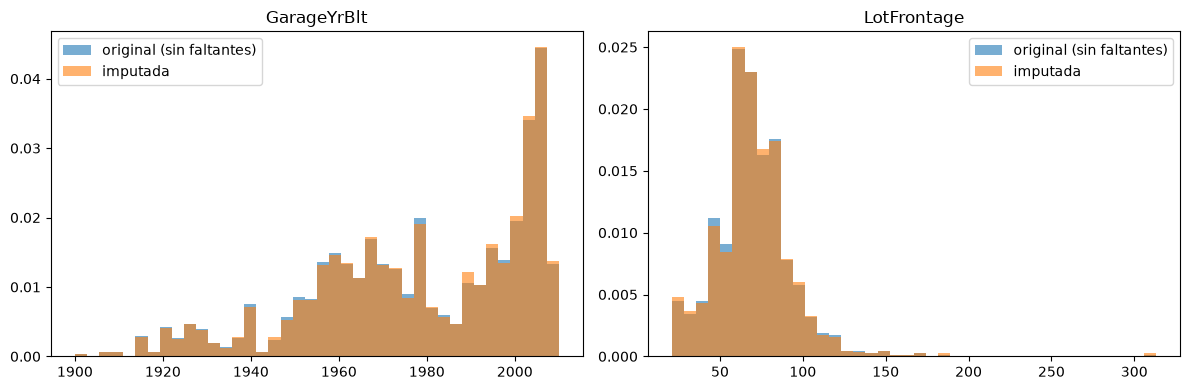

In [8]:
fig, axes = plt.subplots(1, len(num_muestreo), figsize=(6 * len(num_muestreo), 4), squeeze=False)
for ax, col in zip(axes[0], num_muestreo):
    ax.hist(X_train[col].dropna(), bins=40, alpha=0.6, density=True, label="original (sin faltantes)")
    ax.hist(X_train_1[col], bins=40, alpha=0.6, density=True, label="imputada")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

## Paso 2: Codificación de variables categóricas

- **Ordinales** (`OrdinalEncoder` de scikit-learn con el orden de `ORDEN_CATEGORIAS`, envuelto en `SklearnTransformerWrapper` de feature-engine): cada categoría pasa a un entero que respeta su orden, p. ej. `Po=0, Fa=1, TA=2, Gd=3, Ex=4`. Una categoría no vista se codifica como `-1`.
- **Nominales** (`OneHotEncoder` de feature-engine): una columna binaria por categoría. Una categoría que no aparezca en train queda con todas sus columnas en 0.

In [9]:
codificacion = [
    ("codificar_ordinales", SklearnTransformerWrapper(
        transformer=OrdinalEncoder(
            categories=[ORDEN_CATEGORIAS[c] for c in ordinales],
            handle_unknown="use_encoded_value",
            unknown_value=-1,
        ),
        variables=ordinales,
    )),
    ("codificar_nominales", OneHotEncoder(variables=nominales)),
]

X_train_2 = Pipeline(codificacion).fit_transform(X_train_1)

print(f"Columnas: {X_train_1.shape[1]} -> {X_train_2.shape[1]}")
X_train_2[ordinales].head()

Columnas: 29 -> 63


,ExterQual,BsmtQual,KitchenQual,GarageFinish,BsmtFinType1,HeatingQC
Id,,,,,,
255,2.0,2.0,2.0,1.0,2.0,2.0
1067,3.0,3.0,2.0,1.0,0.0,3.0
866,2.0,2.0,2.0,0.0,3.0,2.0
800,2.0,3.0,3.0,0.0,4.0,4.0
381,2.0,2.0,3.0,0.0,1.0,2.0


## Paso 3: Tratamiento de outliers (capping)

Aplica `Winsorizer` a las variables continuas: los valores fuera de `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]` se recortan al límite (no se eliminan filas). Los límites se calculan con `X_train`. La tabla muestra los límites y cuántas casas se recortaron en cada variable.

In [10]:
outliers = [
    ("capping_iqr", Winsorizer(capping_method="iqr", tail="both", fold=1.5, variables=continuas)),
]

pipe_outliers = Pipeline(outliers)
X_train_3 = pipe_outliers.fit_transform(X_train_2)

winsorizer = pipe_outliers.named_steps["capping_iqr"]
pd.DataFrame({
    "limite_inferior": pd.Series(winsorizer.left_tail_caps_),
    "limite_superior": pd.Series(winsorizer.right_tail_caps_),
    "casas_recortadas": (X_train_2[continuas] != X_train_3[continuas]).sum(),
}).round(1)

,limite_inferior,limite_superior,casas_recortadas
GrLivArea,154.0,2768.0,22
GarageArea,-45.9,949.1,17
TotalBsmtSF,76.0,1996.0,56
1stFlrSF,153.4,2112.4,18
YearBuilt,1885.0,2069.0,6
YearRemodAdd,1911.5,2059.5,0
GarageYrBlt,1902.0,2062.0,1
MasVnrArea,-242.6,404.4,75
BsmtFinSF1,-1073.2,1788.8,4
LotFrontage,27.5,111.5,81


## Paso 4: Transformación de variables continuas

Aplica `YeoJohnsonTransformer` solo a las continuas con **|sesgo| > 0.75** (medido en `X_train` después del capping). Los años (`YearBuilt`, `YearRemodAdd`, `GarageYrBlt`) tienen poco sesgo y Yeo-Johnson los lleva a valores enormes (10^71 o más), así que no se transforman. Yeo-Johnson, a diferencia del logaritmo, acepta ceros (p. ej. `MasVnrArea`, `BsmtFinSF1`).

In [11]:
UMBRAL_SESGO = 0.75

sesgo_antes = X_train_3[continuas].skew()
variables_yj = sesgo_antes[sesgo_antes.abs() > UMBRAL_SESGO].index.tolist()

transformacion = [
    ("yeo_johnson", YeoJohnsonTransformer(variables=variables_yj)),
]

pipe_transformacion = Pipeline(transformacion)
X_train_4 = pipe_transformacion.fit_transform(X_train_3)

pd.DataFrame({
    "sesgo_antes": sesgo_antes,
    "sesgo_despues": X_train_4[continuas].skew(),
    "lambda": pd.Series(pipe_transformacion.named_steps["yeo_johnson"].lambda_dict_),
}).round(3)

,sesgo_antes,sesgo_despues,lambda
1stFlrSF,0.664,0.664,NaN
BsmtFinSF1,0.714,0.714,NaN
GarageArea,-0.065,-0.065,NaN
GarageYrBlt,-0.662,-0.662,NaN
GrLivArea,0.593,0.593,NaN
LotFrontage,0.067,0.067,NaN
MasVnrArea,1.294,0.428,-0.249
TotalBsmtSF,0.214,0.214,NaN
YearBuilt,-0.592,-0.592,NaN
YearRemodAdd,-0.500,-0.500,NaN


### 4.1 Distribución antes y después de Yeo-Johnson

Histogramas de cada variable transformada: arriba antes (después del capping), abajo después de Yeo-Johnson.

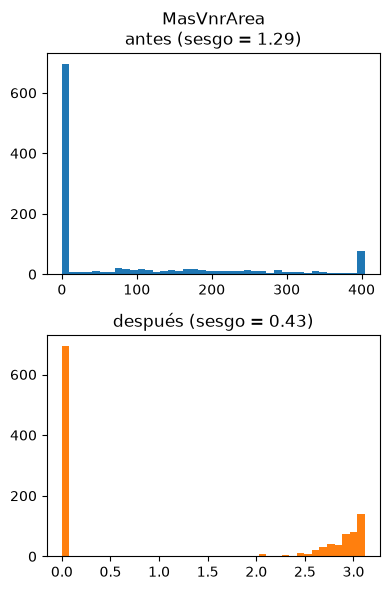

In [12]:
fig, axes = plt.subplots(2, len(variables_yj), figsize=(4 * len(variables_yj), 6), squeeze=False)
for i, col in enumerate(variables_yj):
    axes[0, i].hist(X_train_3[col], bins=40)
    axes[0, i].set_title(f"{col}\nantes (sesgo = {X_train_3[col].skew():.2f})")
    axes[1, i].hist(X_train_4[col], bins=40, color="tab:orange")
    axes[1, i].set_title(f"después (sesgo = {X_train_4[col].skew():.2f})")
plt.tight_layout()
plt.show()

## Paso 5: Escalado de variables

Aplica `StandardScaler` (media 0, desviación estándar 1) a las continuas, discretas y ordinales. Las columnas one-hot no se escalan porque ya son 0/1.

In [13]:
variables_escalar = continuas + discretas + ordinales

escalado = [
    ("escalado_estandar", SklearnTransformerWrapper(transformer=StandardScaler(), variables=variables_escalar)),
]

X_train_5 = Pipeline(escalado).fit_transform(X_train_4)

X_train_5[variables_escalar].describe().loc[["mean", "std"]].round(2)

,GrLivArea,GarageArea,TotalBsmtSF,1stFlrSF,YearBuilt,YearRemodAdd,GarageYrBlt,MasVnrArea,BsmtFinSF1,LotFrontage,OverallQual,GarageCars,FullBath,TotRmsAbvGrd,Fireplaces,HalfBath,BsmtFullBath,BedroomAbvGr,KitchenAbvGr,MSSubClass,ExterQual,BsmtQual,KitchenQual,GarageFinish,BsmtFinType1,HeatingQC
mean,0.0,0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Pipeline final

Une los cinco pasos en un único `Pipeline` de scikit-learn, lo ajusta con `X_train` y verifica que produce exactamente el mismo resultado que los pasos aplicados uno por uno.

In [14]:
pipeline_fe = Pipeline(imputacion + codificacion + outliers + transformacion + escalado)
pipeline_fe.fit(X_train)

X_train_fe = pipeline_fe.transform(X_train)
X_valid_fe = pipeline_fe.transform(X_valid)
X_test_fe = pipeline_fe.transform(X_test)

assert np.allclose(X_train_fe.to_numpy(dtype=float), X_train_5.to_numpy(dtype=float))
assert X_train_fe.isna().sum().sum() == X_valid_fe.isna().sum().sum() == X_test_fe.isna().sum().sum() == 0

print(f"X_train_fe: {X_train_fe.shape}")
print(f"X_valid_fe: {X_valid_fe.shape}")
print(f"X_test_fe:  {X_test_fe.shape}")
pipeline_fe

X_train_fe: (1166, 63)
X_valid_fe: (292, 63)
X_test_fe:  (1459, 63)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('descartar_faltantes', ...), ('imputar_mediana', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['Gr...ea', 'Ga...ea', 'To...SF', '1s...SF', ...]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,features_to_drop,['FireplaceQu']
Name,Type,Value
feature_names_in_,list,"['Gr...ea', 'Ga...ea', 'To...SF', '1s...SF', ...]"
features_to_drop_,list,['Fi...Qu']


## Guardado de datasets y pipeline

Guarda los insumos para el notebook de modelado:

- `data/processed/train_fe.csv` y `valid_fe.csv`: features transformadas + `log_SalePrice`.
- `data/processed/test_fe.csv`: features transformadas (sin target), para generar el envío a Kaggle.
- `models/pipeline_fe.joblib`: el pipeline ajustado, para transformar datos nuevos de la misma forma.

En todos los CSV el índice es `Id`.

In [15]:
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

X_train_fe.join(y_train).to_csv(PROCESSED_DATA_DIR / "train_fe.csv")
X_valid_fe.join(y_valid).to_csv(PROCESSED_DATA_DIR / "valid_fe.csv")
X_test_fe.to_csv(PROCESSED_DATA_DIR / "test_fe.csv")
joblib.dump(pipeline_fe, MODELS_DIR / "pipeline_fe.joblib")

for path in [PROCESSED_DATA_DIR / f for f in ["train_fe.csv", "valid_fe.csv", "test_fe.csv"]] + [MODELS_DIR / "pipeline_fe.joblib"]:
    print(f"{path.relative_to(PROJ_ROOT)}")

data/processed/train_fe.csv
data/processed/valid_fe.csv
data/processed/test_fe.csv
models/pipeline_fe.joblib
